# Решение задачи кредитного скоринга 
Решение задачи кредитного скоринга будет представлено в нескольких ноутбуках. В данном ноутбуке будет проведен первичный анализ данных и их подготовка.

## Данные
Датасет соревнования устроен таким образом, что кредиты для тренировочной выборки взяты за период в М месяцев, а кредиты для тестовой выборки взяты за последующие K месяцев.

Каждая запись кредитной истории содержит самую разнообразную информацию о прошлом кредите клиента, например, сумму, отношение клиента к кредиту, дату открытия и закрытия, информацию о просрочках по платежам и др. Все публикуемые данные тщательно анонимизированы.

Целевая переменная – бинарная величина, принимающая значения 0 и 1, где 1 соответствует дефолту клиента по кредиту.

## Проверка решения
Итоговая метрика решения - ROC AUC. Решения принимаются в виде csv-файла с двумя колонками: “id” – уникальный идентификатор и “score” – предсказание дефолта клиента по кредиту.

## Импорт библиотек

In [1]:
# Импорт библиотек
import sys

sys.path.append('../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

from credit_scoring.features.aggregations import build_features
from credit_scoring.utils.read import read_dataset, read_features

pd.set_option('display.max_columns', None)
RANDOM_STATE = 13

## Чтение датасета
Прочитаем все parquet файлы датасета и соберем их в один целый dataframe. Функция чтения сразу приводит признаки к минимальному целочисленному типу: все значения в датасете - небольшие закодированные числа, поэтому int64 избыточен.

In [2]:
# Чтение основного тренировочного датасета
data_df, target_df = read_dataset("../raw_datasets/train_data", "../raw_datasets/train_target.csv")

print(f"Кредитов: {len(data_df):,}, заявок: {data_df.index.nunique():,}")
print(f"Память: {data_df.memory_usage(deep=True).sum() / 2**30:.2f} GB")

Кредитов: 26,162,717, заявок: 3,000,000
Память: 1.56 GB


In [3]:
# Выведем наши данные из тренировочного набора
data_df.head(15)

,rn,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,pre_loans_outstanding,pre_loans_total_overdue,pre_loans_max_overdue_sum,pre_loans_credit_cost_rate,pre_loans5,pre_loans530,pre_loans3060,pre_loans6090,pre_loans90,is_zero_loans5,is_zero_loans530,is_zero_loans3060,is_zero_loans6090,is_zero_loans90,pre_util,pre_over2limit,pre_maxover2limit,is_zero_util,is_zero_over2limit,is_zero_maxover2limit,enc_paym_0,enc_paym_1,enc_paym_2,enc_paym_3,enc_paym_4,enc_paym_5,enc_paym_6,enc_paym_7,enc_paym_8,enc_paym_9,enc_paym_10,enc_paym_11,enc_paym_12,enc_paym_13,enc_paym_14,enc_paym_15,enc_paym_16,enc_paym_17,enc_paym_18,enc_paym_19,enc_paym_20,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,18,9,2,3,16,10,11,3,3,0,2,11,6,16,5,4,8,1,1,1,1,1,16,2,17,1,1,1,0,0,3,3,3,3,3,3,3,3,3,4,3,3,3,3,3,3,3,3,4,3,3,3,4,1,3,4,1,0,0
0,2,18,9,14,14,12,12,0,3,3,0,2,11,6,16,5,4,8,1,1,1,1,1,16,2,17,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,4,1,3,4,1,0,0
0,3,18,9,4,8,1,11,11,0,5,0,2,8,6,16,5,4,8,1,1,1,1,1,15,2,17,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,4,1,2,3,1,1,1
0,4,4,1,9,12,16,7,12,2,3,0,2,4,6,16,5,4,8,0,1,1,1,1,16,2,17,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1,3,3,3,3,3,3,3,3,4,3,3,3,4,1,3,1,1,0,0
0,5,5,12,15,2,11,12,10,2,3,0,2,4,6,16,5,4,8,1,1,1,1,1,16,2,17,1,1,1,0,0,0,0,0,0,0,3,3,3,3,4,3,3,3,3,3,3,3,3,4,3,3,3,4,1,3,4,1,0,0
0,6,5,0,11,8,12,11,4,2,3,0,2,4,6,16,5,4,8,1,1,1,1,1,9,5,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,3,4,3,3,3,4,1,2,3,1,0,1
0,7,3,9,1,2,12,14,15,5,3,0,2,3,6,16,5,4,8,1,1,1,1,1,16,2,17,1,1,1,0,0,0,0,0,0,0,0,3,3,3,4,3,3,3,3,3,3,3,3,4,3,3,3,4,1,3,4,1,0,0
0,8,2,9,2,3,12,14,15,5,3,0,2,13,6,16,5,4,8,1,1,1,1,1,16,2,17,1,1,1,0,0,3,3,3,3,3,3,3,3,3,4,3,3,3,3,3,3,3,3,4,3,3,3,4,1,3,4,1,0,0
0,9,1,9,11,13,14,8,2,5,1,0,2,11,6,16,5,4,8,1,1,1,1,1,1,2,17,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3,3,3,3,3,3,4,3,3,3,4,1,2,4,1,0,0


In [4]:
# Выведем датафрейм с целевым признаком
target_df.head(5)

,flag
id,
0,0
1,0
2,0
3,0
4,0


## EDA - разведочный анализ данных
### Описание признаков
По описанию соревнования признаки кредита делятся на несколько смысловых групп:

| Группа | Признаки | Смысл |
|---|---|---|
| Порядок | `rn` | порядковый номер кредита в кредитной истории |
| Сроки | `pre_since_opened`, `pre_since_confirmed`, `pre_pterm`, `pre_fterm`, `pre_till_pclose`, `pre_till_fclose` | дни с открытия / подтверждения, плановый и фактический срок, дни до закрытия |
| Суммы | `pre_loans_credit_limit`, `pre_loans_next_pay_summ`, `pre_loans_outstanding`, `pre_loans_total_overdue`, `pre_loans_max_overdue_sum`, `pre_loans_credit_cost_rate` | лимит, следующий платёж, остаток долга, текущая и максимальная просрочка, полная стоимость кредита |
| Просрочки | `pre_loans5`, `pre_loans530`, `pre_loans3060`, `pre_loans6090`, `pre_loans90` | число просрочек по длительности |
| Отношения к лимиту | `pre_util`, `pre_over2limit`, `pre_maxover2limit` | остаток / лимит, текущая просрочка / лимит, максимальная просрочка / лимит |
| Флаги | `is_zero_*`, `pclose_flag`, `fclose_flag` | нет просрочек данного типа / отношение равно 0 / срок не определён |
| Статусы платежей | `enc_paym_0` ... `enc_paym_24` | закодированный статус ежемесячного платежа за последние 25 месяцев |
| Категории кредита | `enc_loans_account_holder_type`, `enc_loans_credit_status`, `enc_loans_account_cur`, `enc_loans_credit_type` | тип отношения к кредиту, статус, валюта, тип кредита |

Признаки с префиксом `pre_` - это непрерывные величины, заранее разбитые организаторами на бины (номер бина вместо значения). Признаки `enc_` - закодированные категории. Это важно для агрегации: среднее по номерам бинов ещё имеет смысл (бины упорядочены), а среднее по кодам категорий - уже нет.

### Типы данных
Посмотрим на типы признаков в датасете.

In [5]:
# Посмотрим, признаки каких типов у нас представлены
data_df.dtypes.value_counts()

int8    60
Name: count, dtype: int64

Все 60 признаков целочисленные (после даункаста - int8). Это подтверждает, что все признаки так или иначе закодированы в числа: реально они представляют из себя бины, категории и бинарные флаги.

### Пропуски в данных
Изучим пропуски в наших данных, посмотрим на их количество.

In [6]:
# Посмотрим на общее количество пропусков в данных
print(f"Пропусков в данных: {data_df.isna().sum().sum()}")
print(f"Пропусков в таргете: {target_df.isna().sum().sum()}")

Пропусков в данных: 0
Пропусков в таргете: 0


Пропуски отсутствуют. Высока вероятность, что в данном датасете отсутствие данных уже учтено как отдельный бин / категория признака, поэтому чистых NaN мы не встречаем. Но учитывать это придется.

### Анализ целевой переменной
Изучим целевую переменную, посмотрим на баланс классов для целевой переменной.

Важное замечание - целевая переменная в нашем случае это бинарное значение, случится дефолт или нет у конкретного клиента. А данные в основном датасете представлены для каждого кредита по отдельности. Иными словами, нам придется агрегировать данные из основного датасета для каждой заявки.

In [7]:
# Теперь посмотрим на целевую переменную и баланс классов
target_df['flag'].value_counts(normalize=True)

flag
0    0.964519
1    0.035481
Name: proportion, dtype: float64

По долям класса 1 видно сильный дисбаланс классов: дефолтов около 3.5%. Для ROC-AUC дисбаланс сам по себе не страшен (метрика ранговая), но он важен для калибровки вероятностей и выбора порога.

### Кредитные истории заявок
Проверим, что у каждой заявки есть кредитная история, и посмотрим, сколько кредитов приходится на одну заявку.

In [8]:
# Проверим соответствие id между данными и таргетом
ids_data = data_df.index.unique()
print(f"Заявок в таргете без кредитной истории: {target_df.index.difference(ids_data).size}")
print(f"Заявок в данных без таргета: {ids_data.difference(target_df.index).size}")

# Проверим, что rn - это сквозная нумерация 1..n внутри заявки
n_loans = data_df.groupby(level='id').size().rename('n_loans')
rn_max = data_df.groupby(level='id')['rn'].max()
print(f"Доля заявок, где max(rn) == число кредитов: {(rn_max == n_loans).mean():.4f}")
n_loans.describe()

Заявок в таргете без кредитной истории: 0
Заявок в данных без таргета: 0


Доля заявок, где max(rn) == число кредитов: 1.0000


count    3.000000e+06
mean     8.720906e+00
std      6.176249e+00
min      1.000000e+00
25%      4.000000e+00
50%      7.000000e+00
75%      1.200000e+01
max      5.800000e+01
Name: n_loans, dtype: float64

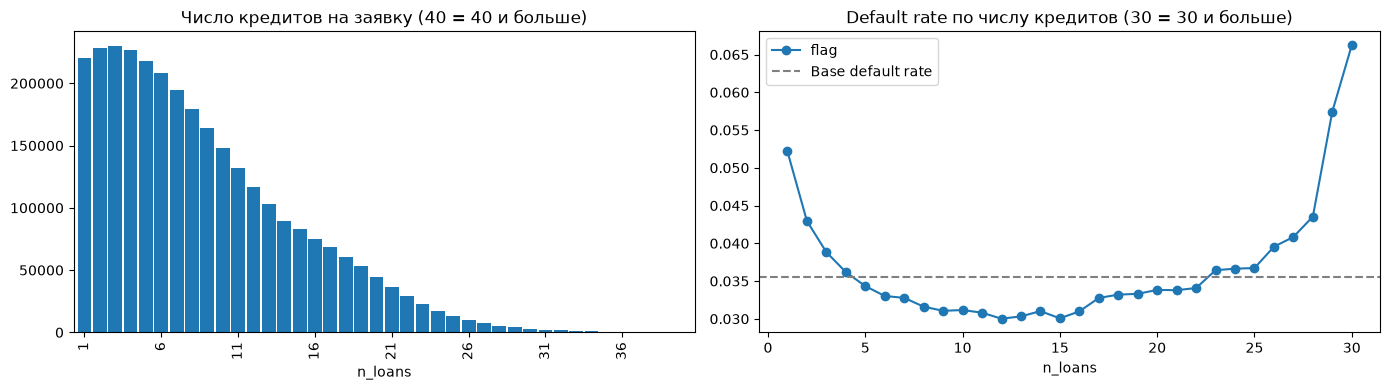

In [9]:
# Распределение числа кредитов и уровень дефолта в зависимости от него
loans_target = target_df.join(n_loans)
base_rate = target_df['flag'].mean()
rate_by_n = loans_target.groupby(loans_target['n_loans'].clip(upper=30))['flag'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
n_loans.clip(upper=40).value_counts().sort_index().plot.bar(ax=axes[0], width=0.9)
axes[0].set_title('Число кредитов на заявку (40 = 40 и больше)')
axes[0].set_xlabel('n_loans')
axes[0].xaxis.set_major_locator(plt.MultipleLocator(5))

rate_by_n.plot(ax=axes[1], marker='o')
axes[1].axhline(base_rate, linestyle='--', color='gray', label='Base default rate')
axes[1].set_title('Default rate по числу кредитов (30 = 30 и больше)')
axes[1].set_xlabel('n_loans')
axes[1].legend()
plt.tight_layout()
plt.show()

Выводы:
- у каждой заявки есть кредитная история и наоборот, `rn` - сквозная нумерация 1..n без пропусков;
- в среднем на заявку приходится ~9 кредитов (медиана 7, максимум 58), у 220 тыс. заявок всего один кредит;
- зависимость уровня дефолта от числа кредитов U-образная: короткая кредитная история (1-3 кредита) и очень длинная (25+) - зоны повышенного риска. Значит, `n_loans` - полезный признак, но связь с таргетом немонотонная.

### Количество уникальных значений
Посмотрим, сколько уникальных значений принимает каждый признак.

In [10]:
# Выведем количество уникальных значений для столбцов
data_df.nunique().sort_values().to_frame('nunique').T

,fclose_flag,pclose_flag,is_zero_maxover2limit,is_zero_over2limit,is_zero_util,is_zero_loans90,pre_loans_total_overdue,is_zero_loans6090,is_zero_loans3060,is_zero_loans530,is_zero_loans5,enc_paym_6,enc_paym_7,enc_paym_8,enc_paym_9,enc_paym_10,enc_paym_11,enc_paym_12,enc_paym_13,enc_paym_14,enc_paym_15,enc_paym_16,enc_paym_17,enc_paym_18,enc_paym_19,enc_paym_20,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_cur,enc_paym_5,enc_paym_4,enc_paym_0,enc_paym_2,enc_paym_1,enc_paym_3,pre_loans_max_overdue_sum,pre_loans6090,pre_loans_outstanding,enc_loans_credit_status,pre_loans_next_pay_summ,enc_loans_account_holder_type,pre_loans90,enc_loans_credit_type,pre_loans3060,pre_loans5,pre_loans_credit_cost_rate,pre_till_fclose,pre_till_pclose,pre_fterm,pre_pterm,pre_since_confirmed,pre_since_opened,pre_util,pre_maxover2limit,pre_over2limit,pre_loans530,pre_loans_credit_limit,rn
nunique,2,2,2,2,2,2,2,2,2,2,2,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,5,5,7,7,7,7,8,10,13,14,16,17,17,18,18,20,20,20,20,20,20,58


Все `pre_` признаки принимают не больше двух десятков значений (номер бина), флаги - 2 значения, категориальные признаки и статусы платежей - единицы значений.

### Связь признаков с таргетом
Посмотрим на уровень дефолта в зависимости от значения признака. Для этого протянем таргет заявки на каждый её кредит. Важная оговорка: на уровне кредита заявки с большим числом кредитов учитываются много раз, поэтому это оценка связи, а не точный уровень дефолта по клиентам.

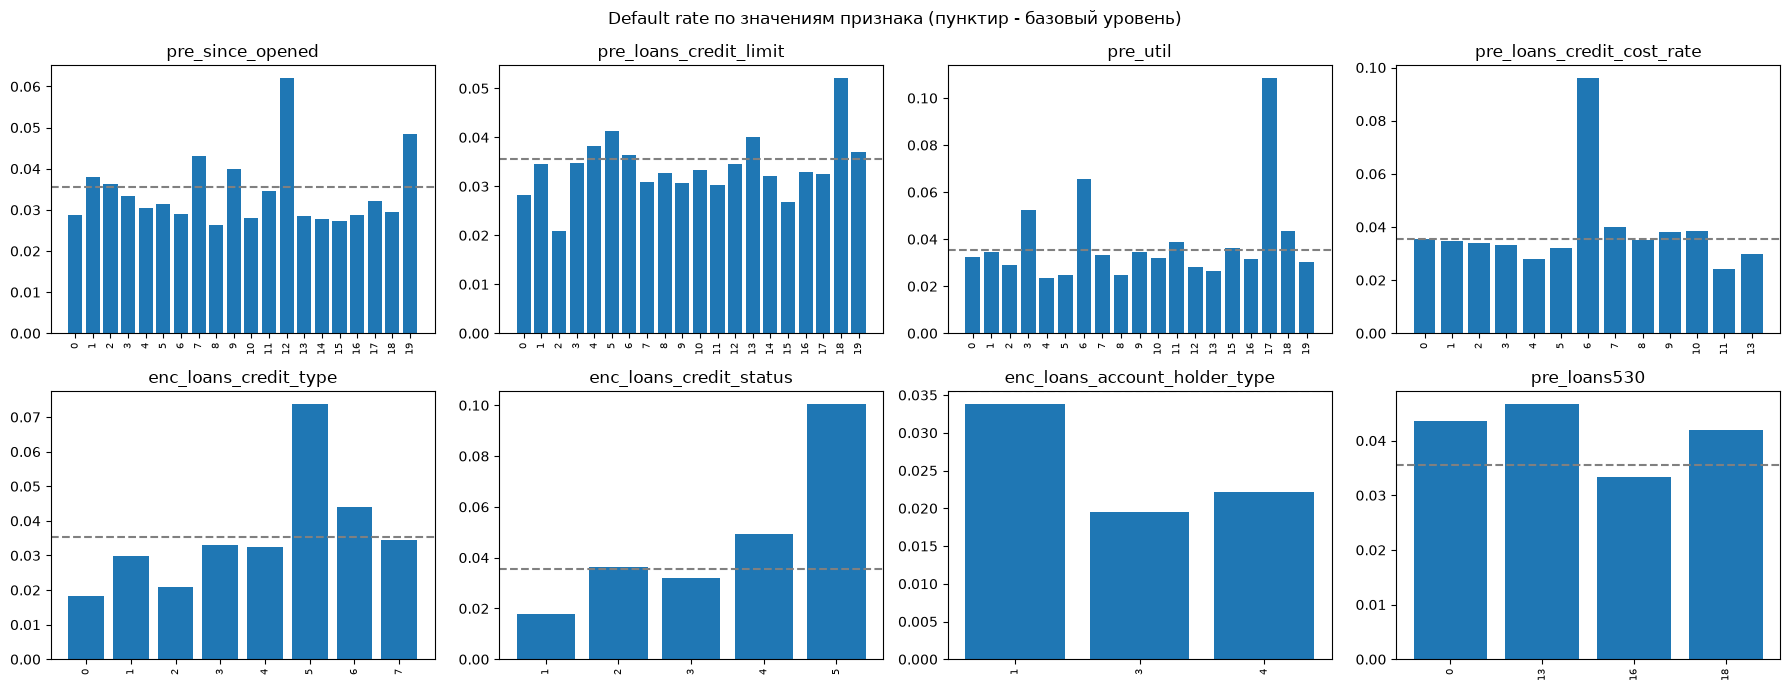

In [11]:
# Протянем таргет заявки на каждый её кредит
loans = data_df.join(target_df)

def default_rate_by_value(df, col):
    """Уровень дефолта и доля кредитов для каждого значения признака."""
    stats = df.groupby(col)['flag'].agg(rate='mean', n='size')
    stats['share'] = stats['n'] / stats['n'].sum()
    return stats

plot_cols = [
    'pre_since_opened', 'pre_loans_credit_limit', 'pre_util', 'pre_loans_credit_cost_rate',
    'enc_loans_credit_type', 'enc_loans_credit_status', 'enc_loans_account_holder_type', 'pre_loans530',
]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    stats = default_rate_by_value(loans, col)
    # Редкие значения (< 0.1% кредитов) не показываем - по ним оценка шумная
    stats = stats[stats['share'] >= 0.001]
    ax.bar(stats.index.astype(str), stats['rate'])
    ax.axhline(base_rate, linestyle='--', color='gray')
    ax.set_title(col)
    ax.tick_params(axis='x', labelsize=7, rotation=90)
fig.suptitle('Default rate по значениям признака (пунктир - базовый уровень)')
plt.tight_layout()
plt.show()

Выводы:
- связь `pre_` признаков с таргетом часто немонотонная: например, в `pre_util` выделяется бин 17, в `pre_loans_credit_cost_rate` - бин 6, в `pre_since_opened` - бин 12. Похоже, номера бинов не всегда упорядочены по исходной величине, поэтому агрегаты вида mean/sum по номерам бинов - грубое приближение. Доли отдельных «рискованных» бинов по заявке могут работать лучше;
- в `pre_loans530` значимую долю кредитов занимают всего 4 значения (0, 13, 16, 18) - номер бина здесь точно не равен числу просрочек;
- категориальные признаки сильно разделяют риск: `enc_loans_credit_status = 5` даёт ~10% дефолтов (в 3 раза выше базового), `enc_loans_credit_type = 5` - ~7.5%. Для них полезнее доля кредитов каждого значения в заявке, чем mode / nunique.

### Статусы ежемесячных платежей
Признаки `enc_paym_0` ... `enc_paym_24` - статусы платежей за последние 25 месяцев. Посмотрим, как распределены статусы по месяцам и какой уровень дефолта соответствует каждому статусу.

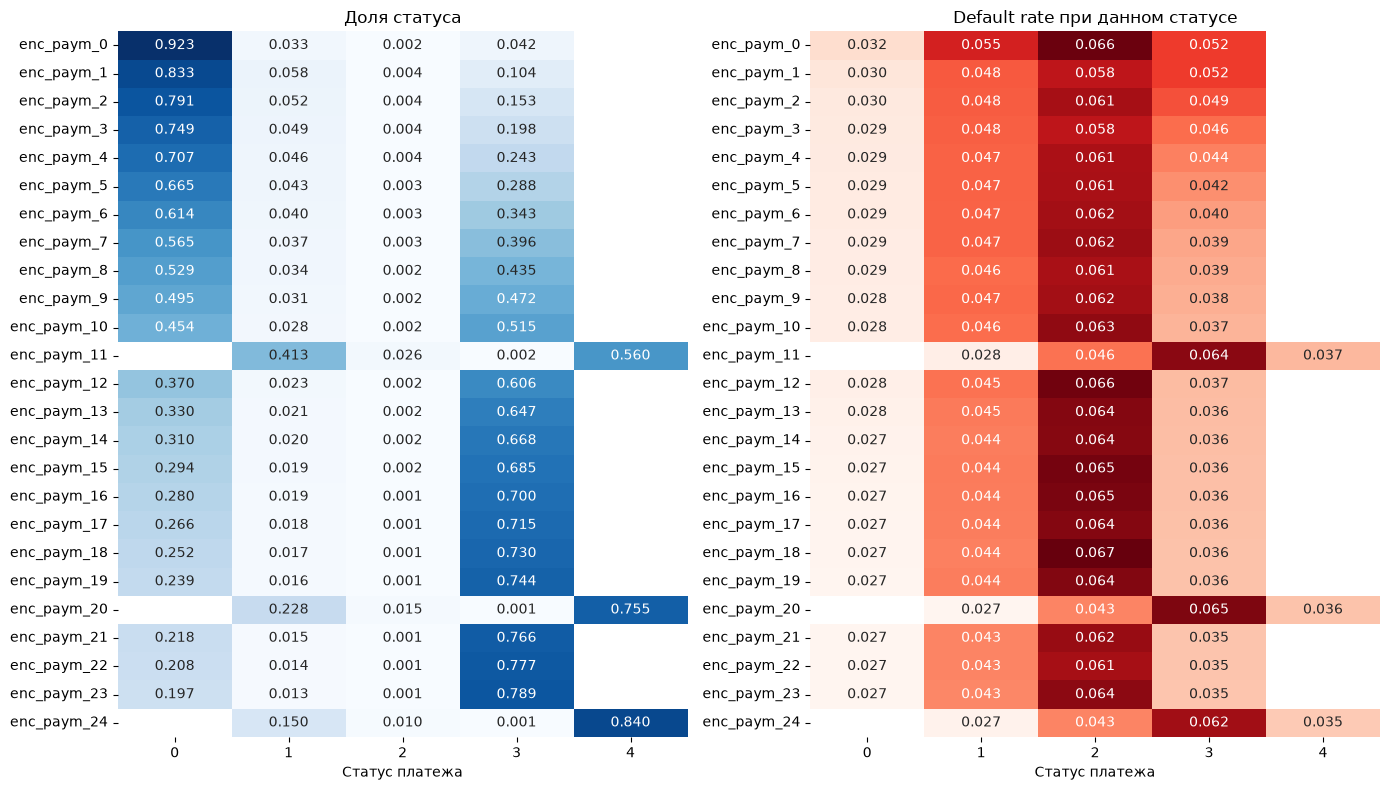

In [12]:
# Доля каждого статуса и уровень дефолта по месяцам
paym_cols = [f'enc_paym_{i}' for i in range(25)]
paym_share = pd.DataFrame({c: loans[c].value_counts(normalize=True) for c in paym_cols}).T.sort_index(axis=1)
paym_rate = pd.DataFrame({c: loans.groupby(c)['flag'].mean() for c in paym_cols}).T.sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
sns.heatmap(paym_share, annot=True, fmt='.3f', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Доля статуса')
sns.heatmap(paym_rate, annot=True, fmt='.3f', cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title('Default rate при данном статусе')
for ax in axes:
    ax.set_xlabel('Статус платежа')
plt.tight_layout()
plt.show()

Выводы:
- в месяцах `enc_paym_11`, `enc_paym_20` и `enc_paym_24` статусы закодированы со сдвигом на +1 (значения 1-4 вместо 0-3): по долям и по уровню дефолта код 1 в этих месяцах соответствует коду 0 в остальных, код 4 - коду 3 и т.д. Перед любыми агрегатами по нескольким месяцам эти колонки нужно привести к общей кодировке, иначе, например, `enc_paym_11_mean` систематически завышен на 1;
- статус 0 доминирует в свежих месяцах и уходит вниз в старых, а статус 3, наоборот, растёт с давностью месяца. Скорее всего, 0 - платёж вовремя, а 3 - нет данных за месяц (кредит ещё не был открыт или уже закрыт);
- самые рискованные статусы - 2 (~6% дефолтов) и 1 (~4.5-5.5%), а у статуса 3 риск ниже. То есть коды не упорядочены по риску, и `mean` / `max` по коду статуса смешивают «просрочку» с «отсутствием истории». Правильнее агрегировать доли каждого статуса по заявке, отдельно для свежих месяцев;
- связь статуса с дефолтом сильнее всего в свежих месяцах (`enc_paym_0`: 0.055-0.066 для статусов 1-2) - давность важна, и это аргумент в пользу признаков по последним месяцам и последним кредитам.

In [13]:
# Освободим память - кредитный уровень с таргетом больше не нужен
del loans, loans_target

### Агрегация признаков
Проведем агрегацию данных, приведя датасет к формату, где одна строка - это одна заявка. Для этого будем использовать различные агрегаты.
Сама функция агрегации написана в одном месте - в src/credit_scoring/features/aggregations.py. За деталями реализации функции агрегации смотреть туда. Функция `build_features` не использует таргет, поэтому одинаково применяется к train и test.

In [14]:
# Сагрегируем данные и присоединим таргет
features = build_features(data_df)
feature_cols = list(features.columns)
train = target_df.join(features, how='left')
del features, data_df
print(train.shape)
train.head(5)

(3000000, 150)


,flag,n_loans,pre_since_opened_mean,pre_since_opened_max,pre_since_opened_sum,pre_since_opened_std,pre_since_confirmed_mean,pre_since_confirmed_max,pre_since_confirmed_sum,pre_since_confirmed_std,pre_pterm_mean,pre_pterm_max,pre_pterm_sum,pre_pterm_std,pre_fterm_mean,pre_fterm_max,pre_fterm_sum,pre_fterm_std,pre_till_pclose_mean,pre_till_pclose_max,pre_till_pclose_sum,pre_till_pclose_std,pre_till_fclose_mean,pre_till_fclose_max,pre_till_fclose_sum,pre_till_fclose_std,pre_loans_credit_limit_mean,pre_loans_credit_limit_max,pre_loans_credit_limit_sum,pre_loans_credit_limit_std,pre_loans_next_pay_summ_mean,pre_loans_next_pay_summ_max,pre_loans_next_pay_summ_sum,pre_loans_next_pay_summ_std,pre_loans_outstanding_mean,pre_loans_outstanding_max,pre_loans_outstanding_sum,pre_loans_outstanding_std,pre_loans_total_overdue_mean,pre_loans_total_overdue_max,pre_loans_total_overdue_sum,pre_loans_total_overdue_std,pre_loans_max_overdue_sum_mean,pre_loans_max_overdue_sum_max,pre_loans_max_overdue_sum_sum,pre_loans_max_overdue_sum_std,pre_loans_credit_cost_rate_mean,pre_loans_credit_cost_rate_max,pre_loans_credit_cost_rate_sum,pre_loans_credit_cost_rate_std,pre_loans5_mean,pre_loans5_max,pre_loans5_sum,pre_loans5_std,pre_loans530_mean,pre_loans530_max,pre_loans530_sum,pre_loans530_std,pre_loans3060_mean,pre_loans3060_max,pre_loans3060_sum,pre_loans3060_std,pre_loans6090_mean,pre_loans6090_max,pre_loans6090_sum,pre_loans6090_std,pre_loans90_mean,pre_loans90_max,pre_loans90_sum,pre_loans90_std,pre_util_mean,pre_util_max,pre_util_sum,pre_util_std,pre_over2limit_mean,pre_over2limit_max,pre_over2limit_sum,pre_over2limit_std,pre_maxover2limit_mean,pre_maxover2limit_max,pre_maxover2limit_sum,pre_maxover2limit_std,is_zero_loans5_mean,is_zero_loans530_mean,is_zero_loans3060_mean,is_zero_loans6090_mean,is_zero_loans90_mean,is_zero_util_mean,is_zero_over2limit_mean,is_zero_maxover2limit_mean,pclose_flag_mean,fclose_flag_mean,enc_loans_account_holder_type_nunique,enc_loans_account_holder_type_mode_value,enc_loans_credit_status_nunique,enc_loans_credit_status_mode_value,enc_loans_credit_type_nunique,enc_loans_credit_type_mode_value,enc_loans_account_cur_nunique,enc_loans_account_cur_mode_value,enc_paym_0_mean,enc_paym_0_max,enc_paym_1_mean,enc_paym_1_max,enc_paym_2_mean,enc_paym_2_max,enc_paym_3_mean,enc_paym_3_max,enc_paym_4_mean,enc_paym_4_max,enc_paym_5_mean,enc_paym_5_max,enc_paym_6_mean,enc_paym_6_max,enc_paym_7_mean,enc_paym_7_max,enc_paym_8_mean,enc_paym_8_max,enc_paym_9_mean,enc_paym_9_max,enc_paym_10_mean,enc_paym_10_max,enc_paym_11_mean,enc_paym_11_max,enc_paym_12_mean,enc_paym_12_max,enc_paym_13_mean,enc_paym_13_max,enc_paym_14_mean,enc_paym_14_max,enc_paym_15_mean,enc_paym_15_max,enc_paym_16_mean,enc_paym_16_max,enc_paym_17_mean,enc_paym_17_max,enc_paym_18_mean,enc_paym_18_max,enc_paym_19_mean,enc_paym_19_max,enc_paym_20_mean,enc_paym_20_max,enc_paym_21_mean,enc_paym_21_max,enc_paym_22_mean,enc_paym_22_max,enc_paym_23_mean,enc_paym_23_max,enc_paym_24_mean,enc_paym_24_max
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,10,8.100000,18,81,7.030884,7.600000,12,76,3.864367,7.100000,15,71,5.466057,7.500000,14,75,4.719934,11.400000,16,114,4.351245,10.700000,14,107,2.451757,9.600000,16,96,5.680376,3.100000,5,31,1.663330,2.900000,5,29,0.994429,0.0,0,0,0.0,2.000000,2,20,0.000000,8.000000,13,80,3.858612,6.0,6,60,0.0,16.000000,16,160,0.000000,5.0,5,50,0.0,4.0,4,40,0.0,8.0,8,80,0.0,13.600000,16,136,4.926121,2.300000,5,23,0.948683,15.700000,17,157,4.110961,0.900000,1.000000,1.000000,1.000000,1.000000,0.600000,0.900000,0.900000,0.100000,0.200000,1,1,2,3,3,4,1,1,0.100000,1,0.000000,0,0.600000,3,0.600000,3,0.600000,3,0.600000,3,0.900000,3,1.200000,3,1.5,3,1.500000,3,1.500000,3,2.500000,4,1.800000,3,1.800000,3,2.100000,3,2.100000,3,2.100000,3,2.100000,3,2.100000,3,2.400000,3,3.400000,4,2.400000,3,2.400000,3,2.400000,3,4.000000,4
1,0,14,11.428571,18,160,4.1

In [15]:
# Пропуски после агрегации
na = train.isna().sum()
print(f"Заявок с одним кредитом: {(train['n_loans'] == 1).sum():,}")
na[na > 0].head()

Заявок с одним кредитом: 220,545


pre_since_opened_std       220545
pre_since_confirmed_std    220545
pre_pterm_std              220545
pre_fterm_std              220545
pre_till_pclose_std        220545
dtype: int64

Пропуски после агрегации появляются только в `*_std` - у заявок с одним кредитом стандартное отклонение не определено. Градиентный бустинг обрабатывает NaN сам, поэтому заполнять их не будем.

### Дрейф данных
По описанию соревнования тестовые кредиты взяты за период, следующий за тренировочным. Проверим, есть ли в данных временная структура: разобьём тренировочные заявки на 10 равных групп по порядку `id` и посмотрим, как меняются уровень дефолта и признаки.

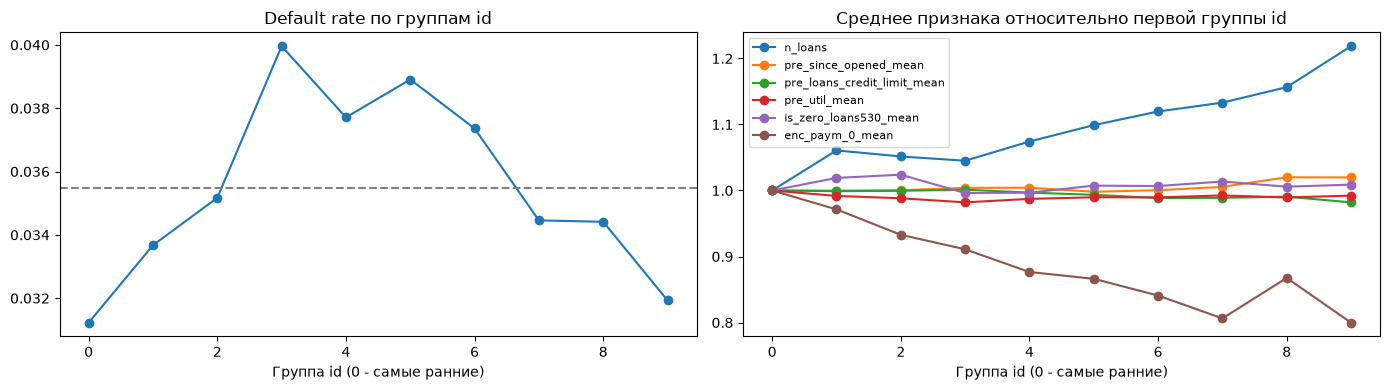

,n_loans,pre_since_opened_mean,pre_loans_credit_limit_mean,pre_util_mean,is_zero_loans530_mean,enc_paym_0_mean,flag
id_decile,,,,,,,
0,7.9584,9.2803,9.7356,13.4505,0.8305,0.1930,0.0312
1,8.4414,9.2791,9.7253,13.3395,0.8463,0.1875,0.0337
2,8.3685,9.2839,9.7310,13.2916,0.8504,0.1801,0.0352
3,8.3169,9.3167,9.7477,13.2087,0.8273,0.1759,0.0400
4,8.5487,9.3190,9.7046,13.2790,0.8278,0.1692,0.0377
5,8.7458,9.2622,9.6717,13.3122,0.8366,0.1672,0.0389
6,8.9105,9.2840,9.6242,13.3103,0.8361,0.1623,0.0374
7,9.0173,9.3315,9.6269,13.3492,0.8418,0.1557,0.0345
8,9.2038,9.4662,9.6449,13.3082,0.8353,0.1675,0.0344


In [16]:
# Разобьём заявки на 10 групп по порядку id
id_decile = pd.Series(pd.qcut(train.index, 10, labels=False), index=train.index, name='id_decile')
drift_cols = [
    'n_loans', 'pre_since_opened_mean', 'pre_loans_credit_limit_mean',
    'pre_util_mean', 'is_zero_loans530_mean', 'enc_paym_0_mean',
]
by_decile = train[drift_cols + ['flag']].groupby(id_decile).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_decile['flag'].plot(ax=axes[0], marker='o')
axes[0].axhline(base_rate, linestyle='--', color='gray')
axes[0].set_title('Default rate по группам id')
(by_decile[drift_cols] / by_decile[drift_cols].iloc[0]).plot(ax=axes[1], marker='o')
axes[1].set_title('Среднее признака относительно первой группы id')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel('Группа id (0 - самые ранние)')
plt.tight_layout()
plt.show()
by_decile.round(4)

Проверим дрейф формально через adversarial validation: обучим классификатор отличать одну выборку от другой. Если ROC-AUC около 0.5 - выборки неотличимы, чем выше - тем сильнее различаются распределения признаков. Сравним три пары:
- две случайные половины train - контроль, ожидаем 0.5;
- ранние и поздние заявки train (первые и последние 20% по `id`);
- train и test.

In [17]:
# Сагрегируем тестовую выборку той же функцией
test_features = build_features(read_features("../raw_datasets/test_data"))
print(f"Заявок в test: {len(test_features):,}, id от {test_features.index.min()} до {test_features.index.max()}")
print(f"id в train: от {train.index.min()} до {train.index.max()}")

Заявок в test: 500,000, id от 3000000 до 3499999
id в train: от 0 до 2999999


In [18]:
def adversarial_auc(a, b, n=200_000):
    """ROC-AUC классификатора, отличающего выборку a от выборки b, и важность признаков."""
    a = a.sample(min(n, len(a)), random_state=RANDOM_STATE)[feature_cols]
    b = b.sample(min(n, len(b)), random_state=RANDOM_STATE)[feature_cols]
    X = pd.concat([a, b])
    y = np.r_[np.zeros(len(a)), np.ones(len(b))]
    model = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, tree_method='hist', random_state=RANDOM_STATE)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    auc = cross_val_score(model, X, y, cv=cv, scoring='roc_auc').mean()
    model.fit(X, y)
    importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    return auc, importance

# Случайное разбиение train пополам - контрольная пара
random_half = np.random.default_rng(RANDOM_STATE).random(len(train)) < 0.5

# Выборки собираем лениво, чтобы не держать в памяти копии всех пар сразу
pairs = {
    'random half vs random half': lambda: (train[random_half], train[~random_half]),
    'train early 20% vs late 20%': lambda: (train[id_decile <= 1], train[id_decile >= 8]),
    'train vs test': lambda: (train, test_features),
}
av_results, av_importance = {}, {}
for name, make_pair in pairs.items():
    av_results[name], av_importance[name] = adversarial_auc(*make_pair())
    print(f"{name}: ROC-AUC = {av_results[name]:.4f}")

random half vs random half: ROC-AUC = 0.4998


train early 20% vs late 20%: ROC-AUC = 0.8044


train vs test: ROC-AUC = 0.7938


In [19]:
# Какие признаки сильнее всего отличают выборки
pd.DataFrame({name: imp.head(10).index for name, imp in av_importance.items() if name != 'random half vs random half'})

,train early 20% vs late 20%,train vs test
0,pre_over2limit_max,pre_over2limit_max
1,pre_loans_credit_cost_rate_max,pre_loans_credit_cost_rate_std
2,pre_loans_max_overdue_sum_std,pre_over2limit_std
3,enc_loans_credit_type_mode_value,enc_paym_24_mean
4,pre_since_confirmed_max,fclose_flag_mean
5,is_zero_loans6090_mean,pre_loans_max_overdue_sum_std
6,pre_loans_max_overdue_sum_max,pre_till_pclose_mean
7,pre_since_opened_max,pre_since_opened_max
8,pre_over2limit_std,pclose_flag_mean
9,enc_loans_account_holder_type_nunique,pre_since_confirmed_max


Выводы:
- контрольная пара (две случайные половины train) даёт ROC-AUC 0.50, как и ожидалось - метод работает;
- ранние и поздние заявки train различаются с ROC-AUC **0.80**, train и test - с ROC-AUC **0.79**. Это сильный дрейф: порядок `id` соответствует времени, а test (id 3 000 000+) идёт сразу после train;
- плавно меняются и сами признаки: число кредитов на заявку растёт с `id` (+22% к последней группе), доля статуса 0 в последнем месяце падает; уровень дефолта по группам немонотонный (от 3.1% до 4.0%);
- больше всего выборки отличают признаки «давности» и отношения к лимиту: `pre_over2limit_max`, `pre_loans_credit_cost_rate_*`, `pre_since_confirmed_max`, `pre_since_opened_max`.

Главное следствие для моделирования: StratifiedKFold с перемешиванием даёт оптимистичную оценку, потому что модель видит в обучении заявки из того же периода, что и в валидации. Основной валидацией должен быть out-of-time holdout - последние ~20% train по `id`. Признаки, сильно дрейфующие во времени и слабо связанные с таргетом, - кандидаты на удаление.

### Сохранение
Сохраним сагрегированные train и test в parquet: он в разы компактнее и быстрее CSV и сохраняет типы колонок.

In [20]:
# Сохраним сагрегированные датафреймы
train.to_parquet('../artifacts/aggregated_df.parquet')
test_features.to_parquet('../artifacts/test_features.parquet')

## Итоги EDA
1. Данные чистые: пропусков нет, у каждой заявки есть кредитная история, `rn` - сквозная нумерация. 26 млн кредитов на 3 млн заявок, дефолтов 3.5%.
2. Все признаки закодированы: `pre_` - номера бинов (не всегда упорядоченные по риску), `enc_` - категории. Агрегаты mean/max по кодам категорий и статусов платежей - грубые; лучше доли значений по заявке.
3. Статусы платежей `enc_paym_11`, `enc_paym_20`, `enc_paym_24` закодированы со сдвигом на +1 - это нужно исправить перед агрегацией по месяцам.
4. Свежие месяцы и последние кредиты несут больше сигнала, чем история целиком.
5. В данных сильный временной дрейф по `id` (adversarial ROC-AUC 0.80 внутри train и 0.79 train vs test) - валидация должна быть out-of-time.

Сагрегированные train и test сохранены в `artifacts/aggregated_df.parquet` и `artifacts/test_features.parquet`. Набор признаков пока оставлен прежним, чтобы следующие ноутбуки работали без изменений; улучшение признаков по выводам выше - отдельный шаг.